# Analisis Dataset Fulfilment Center

Notebook ini mengikuti alur template `main.ipynb`, tetapi disesuaikan dengan file `fulfilment_center_info.csv`. Dataset ini berisi informasi pusat pemenuhan pesanan, bukan riwayat jumlah pesanan. Karena itu, analisis dan pemodelan di notebook ini berfokus pada eksplorasi serta pengelompokan (*clustering*) pusat pemenuhan berdasarkan luas operasional (`op_area`).

# 1. Business Understanding

### 1.1 Pernyataan Masalah

Pusat pemenuhan pesanan memiliki karakteristik berbeda, seperti tipe pusat, lokasi administratif, dan luas area operasional. Memahami karakteristik tersebut dapat membantu eksplorasi data dan melihat apakah pusat-pusat tersebut dapat dikelompokkan berdasarkan luas area operasionalnya.

**Batasan:** file yang tersedia hanya berisi metadata pusat pemenuhan. File ini tidak memiliki jumlah pesanan atau data transaksi, sehingga belum dapat digunakan untuk memprediksi permintaan makanan.

### 1.2 Business Objective

1. Memahami karakteristik pusat pemenuhan pesanan.
2. Membandingkan distribusi luas area operasional berdasarkan tipe pusat.
3. Mengelompokkan pusat berdasarkan `op_area` menggunakan K-Means sebagai analisis eksploratif.

### 1.3 Data Science Objective

Melakukan eksplorasi data dan menerapkan K-Means clustering pada variabel `op_area`. Karena hanya satu fitur numerik operasional yang tersedia, hasil cluster harus dipahami sebagai pengelompokan berdasarkan luas area saja, bukan performa atau kapasitas pesanan.

### 1.4 Pertanyaan Analisis

1. Bagaimana distribusi tipe pusat pemenuhan?
2. Bagaimana sebaran luas area operasional?
3. Bagaimana pusat pemenuhan dapat dikelompokkan berdasarkan luas area operasional?

# 2. Data Gathering

### 2.1 Import Library

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)


### 2.2 Memuat Dataset

Pastikan `fulfilment_center_info.csv` berada di folder yang sama dengan notebook.

In [2]:
file_path = "fulfilment_center_info.csv"
df = pd.read_csv(file_path)

df.head()


,center_id,city_code,region_code,center_type,op_area
0,11,679,56,TYPE_A,3.7
1,13,590,56,TYPE_B,6.7
2,124,590,56,TYPE_C,4.0
3,66,648,34,TYPE_A,4.1
4,94,632,34,TYPE_C,3.6


### 2.3 Memahami Struktur Dataset

In [3]:
print("Ukuran dataset:", df.shape)
print("\nNama kolom:", df.columns.tolist())
print("\nTipe data:")
display(df.dtypes.to_frame("Tipe Data"))
print("\nInformasi dataset:")
df.info()


Ukuran dataset: (77, 5)

Nama kolom: ['center_id', 'city_code', 'region_code', 'center_type', 'op_area']

Tipe data:


,Tipe Data
center_id,int64
city_code,int64
region_code,int64
center_type,str
op_area,float64



Informasi dataset:
<class 'pandas.DataFrame'>
RangeIndex: 77 entries, 0 to 76
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   center_id    77 non-null     int64  
 1   city_code    77 non-null     int64  
 2   region_code  77 non-null     int64  
 3   center_type  77 non-null     str    
 4   op_area      77 non-null     float64
dtypes: float64(1), int64(3), str(1)
memory usage: 3.6 KB


### 2.4 Arti Tiap Kolom

| Kolom | Keterangan | Peran |
|---|---|---|
| `center_id` | Identitas pusat pemenuhan | Identifier, bukan fitur numerik untuk jarak |
| `city_code` | Kode kota | Kode kategori/lokasi |
| `region_code` | Kode wilayah | Kode kategori/lokasi |
| `center_type` | Tipe pusat pemenuhan | Variabel kategori |
| `op_area` | Luas area operasional | Fitur numerik untuk clustering |

# 3. EDA

### 3.1 Pemeriksaan nilai kosong dan duplikat

In [4]:
print("Nilai kosong per kolom:")
display(df.isna().sum().to_frame("Jumlah Missing Value"))

print("Jumlah baris duplikat:", df.duplicated().sum())
print("Jumlah center_id unik:", df["center_id"].nunique())


Nilai kosong per kolom:


,Jumlah Missing Value
center_id,0
city_code,0
region_code,0
center_type,0
op_area,0


Jumlah baris duplikat: 0
Jumlah center_id unik: 77


### 3.2 Statistik deskriptif

In [5]:
display(df.describe(include="all").T)


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
center_id,77.0,NaN,NaN,NaN,83.142857,46.090219,10.0,50.0,77.0,110.0,186.0
city_code,77.0,NaN,NaN,NaN,600.662338,66.720274,456.0,553.0,596.0,651.0,713.0
region_code,77.0,NaN,NaN,NaN,56.493506,18.126473,23.0,34.0,56.0,77.0,93.0
center_type,77,3,TYPE_A,43,NaN,NaN,NaN,NaN,NaN,NaN,NaN
op_area,77.0,NaN,NaN,NaN,3.985714,1.106406,0.9,3.5,3.9,4.4,7.0


### 3.3 Distribusi tipe pusat

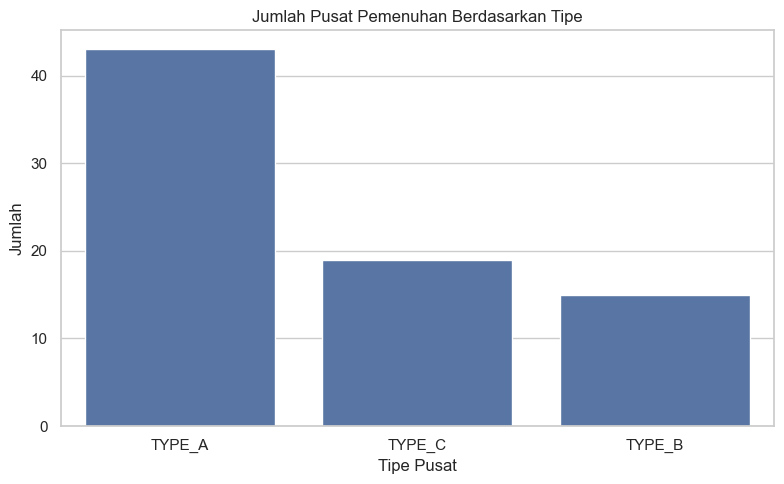

In [6]:
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="center_type", order=df["center_type"].value_counts().index)
plt.title("Jumlah Pusat Pemenuhan Berdasarkan Tipe")
plt.xlabel("Tipe Pusat")
plt.ylabel("Jumlah")
plt.tight_layout()
plt.show()


### 3.4 Distribusi luas area operasional

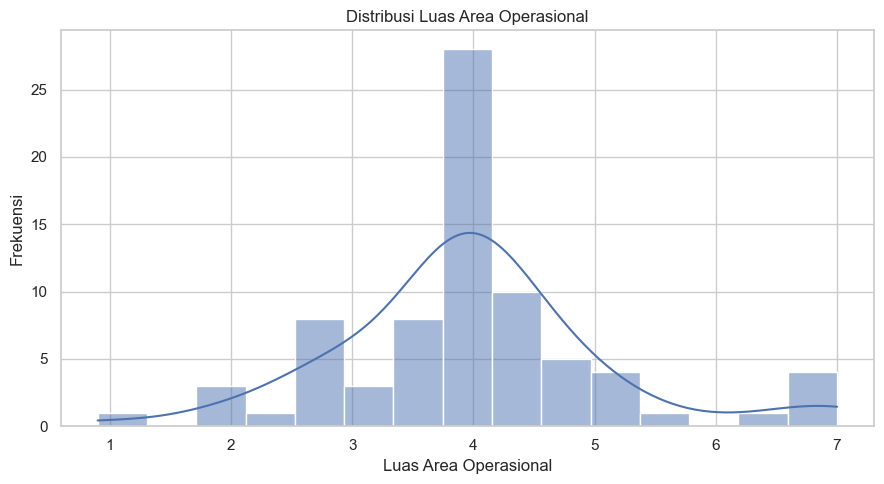

In [7]:
plt.figure(figsize=(9, 5))
sns.histplot(data=df, x="op_area", bins=15, kde=True)
plt.title("Distribusi Luas Area Operasional")
plt.xlabel("Luas Area Operasional")
plt.ylabel("Frekuensi")
plt.tight_layout()
plt.show()


### 3.5 Luas area berdasarkan tipe pusat

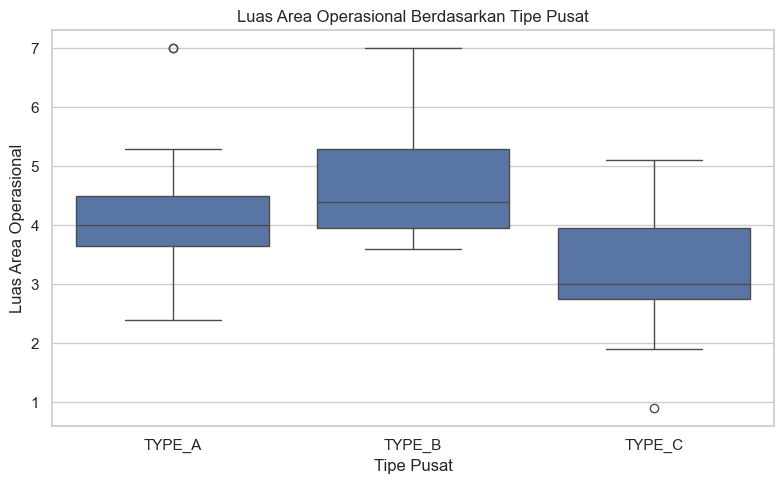

In [8]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="center_type", y="op_area")
plt.title("Luas Area Operasional Berdasarkan Tipe Pusat")
plt.xlabel("Tipe Pusat")
plt.ylabel("Luas Area Operasional")
plt.tight_layout()
plt.show()


# 4. Data Cleaning and Preprocessing

### 4.1 Membersihkan data

Kode berikut menghapus baris duplikat, mengubah `op_area` menjadi numerik, dan menghapus baris yang tidak memiliki nilai pada kolom penting. Kode lokasi dan ID tidak diperlakukan sebagai angka kontinu.

In [9]:
df_clean = df.copy()

df_clean = df_clean.drop_duplicates()
df_clean["op_area"] = pd.to_numeric(df_clean["op_area"], errors="coerce")

kolom_penting = ["center_id", "center_type", "op_area"]
df_clean = df_clean.dropna(subset=kolom_penting)

print("Ukuran sebelum cleaning:", df.shape)
print("Ukuran setelah cleaning:", df_clean.shape)
print("\nMissing value setelah cleaning:")
display(df_clean.isna().sum().to_frame("Jumlah Missing Value"))


Ukuran sebelum cleaning: (77, 5)
Ukuran setelah cleaning: (77, 5)

Missing value setelah cleaning:


,Jumlah Missing Value
center_id,0
city_code,0
region_code,0
center_type,0
op_area,0


### 4.2 Menyiapkan fitur clustering

In [10]:
# Clustering menggunakan luas area operasional saja.
# center_id, city_code, dan region_code merupakan identitas/kode, bukan ukuran numerik kontinu.
X = df_clean[["op_area"]].copy()

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Jumlah data yang digunakan:", X_scaled.shape[0])


Jumlah data yang digunakan: 77


# 5. Modelling

### 5.1 Menentukan jumlah cluster

Silhouette Score digunakan sebagai panduan untuk membandingkan beberapa nilai K. Jika jumlah data atau variasi nilai `op_area` terlalu kecil, evaluasi silhouette mungkin tidak dapat dihitung untuk semua K.

In [11]:
hasil_k = []
n_data = len(X_scaled)

for k in range(2, min(6, n_data)):
    kmeans_uji = KMeans(n_clusters=k, random_state=42, n_init=10)
    label_uji = kmeans_uji.fit_predict(X_scaled)

    if len(set(label_uji)) > 1:
        skor = silhouette_score(X_scaled, label_uji)
        hasil_k.append({"Jumlah Cluster (K)": k, "Silhouette Score": skor})

hasil_k_df = pd.DataFrame(hasil_k)

if not hasil_k_df.empty:
    display(hasil_k_df)
    k_terbaik = int(hasil_k_df.loc[hasil_k_df["Silhouette Score"].idxmax(), "Jumlah Cluster (K)"])
else:
    k_terbaik = 3 if n_data >= 3 else 1
    print("Silhouette Score tidak dapat dihitung. Menggunakan K =", k_terbaik)

print("Jumlah cluster yang digunakan:", k_terbaik)


,Jumlah Cluster (K),Silhouette Score
0,2,0.515414
1,3,0.639180
2,4,0.632181
3,5,0.649175


Jumlah cluster yang digunakan: 5


### 5.2 Melatih model K-Means

In [12]:
if k_terbaik >= 2 and len(X_scaled) >= k_terbaik:
    model = KMeans(n_clusters=k_terbaik, random_state=42, n_init=10)
    df_clean["cluster"] = model.fit_predict(X_scaled)
else:
    df_clean["cluster"] = 0

display(df_clean[["center_id", "center_type", "op_area", "cluster"]].head(10))


,center_id,center_type,op_area,cluster
0,11,TYPE_A,3.7,3
1,13,TYPE_B,6.7,2
2,124,TYPE_C,4.0,3
3,66,TYPE_A,4.1,3
4,94,TYPE_C,3.6,3
5,64,TYPE_A,4.4,0
6,129,TYPE_A,3.9,3
7,139,TYPE_C,2.8,1
8,88,TYPE_A,4.1,3
9,143,TYPE_B,3.8,3


# 6. Evaluasi

### 6.1 Profil setiap cluster

In [13]:
profil_cluster = (
    df_clean.groupby("cluster")
    .agg(
        jumlah_center=("center_id", "count"),
        rata_rata_op_area=("op_area", "mean"),
        minimum_op_area=("op_area", "min"),
        maksimum_op_area=("op_area", "max")
    )
    .round(2)
)

display(profil_cluster)


,jumlah_center,rata_rata_op_area,minimum_op_area,maksimum_op_area
cluster,,,,
0,18,4.74,4.4,5.6
1,12,2.82,2.4,3.2
2,5,6.80,6.3,7.0
3,38,3.86,3.4,4.2
4,4,1.70,0.9,2.0


### 6.2 Visualisasi hasil clustering

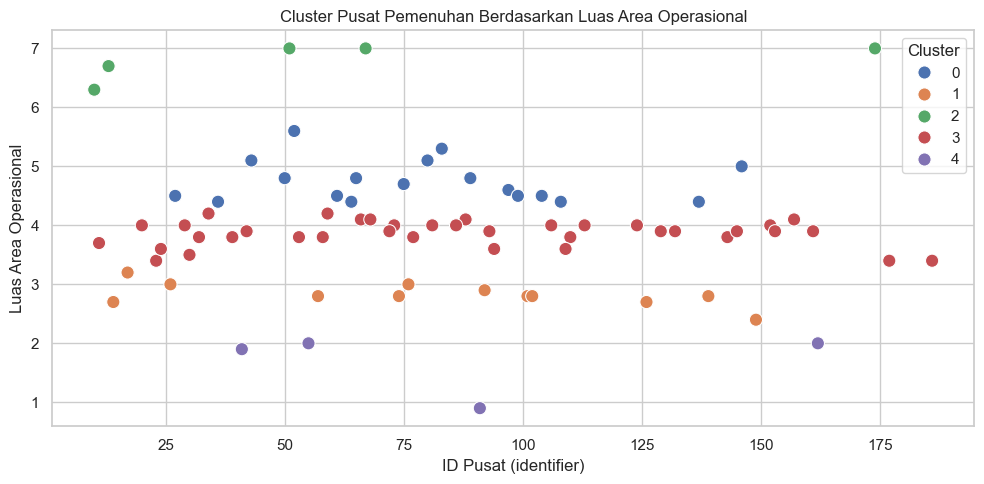

In [14]:
plt.figure(figsize=(10, 5))
sns.scatterplot(
    data=df_clean,
    x="center_id",
    y="op_area",
    hue="cluster",
    palette="deep",
    s=90
)
plt.title("Cluster Pusat Pemenuhan Berdasarkan Luas Area Operasional")
plt.xlabel("ID Pusat (identifier)")
plt.ylabel("Luas Area Operasional")
plt.legend(title="Cluster")
plt.tight_layout()
plt.show()


### 6.3 Interpretasi

Cluster dengan rata-rata `op_area` lebih rendah berisi pusat dengan area operasional relatif kecil, sedangkan cluster dengan rata-rata lebih tinggi berisi pusat dengan area operasional relatif besar. Penamaan seperti kecil, sedang, dan besar perlu disesuaikan dengan nilai rata-rata tiap cluster yang dihasilkan. Hasil ini hanya menggambarkan luas area, bukan jumlah pesanan atau produktivitas.

# 7. Konklusi

Notebook ini melakukan pemeriksaan kualitas data, eksplorasi distribusi tipe pusat dan luas area, serta clustering K-Means berdasarkan `op_area`. Hasil cluster dapat membantu memahami variasi luas area operasional antar pusat pemenuhan.

**Catatan penting:** jika tujuan proyek tetap memprediksi jumlah pesanan makanan (*food demand forecasting*), file ini saja belum cukup. Diperlukan dataset historis seperti `train.csv` yang memuat target `num_orders`, serta file informasi makanan (`meal_info.csv`) bila ingin menggabungkan karakteristik makanan. Setelah file tersebut tersedia, model regresi/peramalan dapat dibuat sesuai tujuan proyek awal.